# 4 — CTGAN synthetic data (train fold only)

CTGAN learns the joint distribution of predictors (+ BMD) from **real train rows only**. We deliberately exclude:

- `SEQN`, `TSCORE`, `TSCORE_ROUNDED`, `TARGET` from generator training
- Any test or external rows from the seed

After sampling, we **recompute TARGET** from generated BMD and `OSQ060` using the same rule as real data.

> **Runtime note:** Default `epochs=300` is suitable for pipeline testing. Increase to 3000–10000 for publication-quality synthetic data. **Best and faster results** with `epochs=7000` (as used here)

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer

from experiment_utils import (
    TRAIN_PATH,
    CTGAN_POOL_PATH,
    METADATA_PATH,
    MODEL_FEATURES,
    LABEL_COL,
    RANDOM_STATE,
    add_labels_to_synthetic,
    ensure_dirs,
    set_reproducibility,
)

ensure_dirs()
set_reproducibility(RANDOM_STATE)

CTGAN_EPOCHS = 7000
POOL_SIZE = 10_000

## 4.1 Load train fold and define CTGAN inputs

In [2]:
train_df = pd.read_csv(TRAIN_PATH)
print(f'Train rows for CTGAN: {len(train_df)}')

# Predictors for the generator: model features + BMD (OSQ060 needed for TARGET rule)
ctgan_cols = ['DXXNKBMD'] + MODEL_FEATURES + ['OSQ060']
ctgan_train = train_df[ctgan_cols].copy()
ctgan_train.head()

Train rows for CTGAN: 1813


,DXXNKBMD,RIDAGEYR,INDFMPIR,BMXBMI,LBXSCK,LBDSCHSI,LBXSAPSI,LBXSUA,LBDSTPSI,LBDSGBSI,LBXSOSSI,LBXGH,LBXMCVSI,LBXRDW,LBXNEPCT,LBXMOPCT,RIAGENDR,OSQ150,DIQ010,OSQ060
0,0.859,60.0,4.57,33.0,199.0,4.422,93.0,7.6,67.0,32.0,284.0,7.5,86.3,15.3,52.2,6.8,1.0,2.0,1.0,2.0
1,1.096,51.0,0.56,20.4,700.0,4.862,71.0,3.8,75.0,32.0,273.0,5.4,95.6,13.9,50.3,6.8,1.0,2.0,2.0,2.0
2,1.174,70.0,3.52,27.1,196.0,4.526,70.0,4.3,75.0,37.0,284.0,5.9,92.3,13.2,53.1,13.4,2.0,2.0,2.0,2.0
3,0.554,80.0,2.89,27.0,106.0,3.543,140.0,5.6,68.0,31.0,292.0,6.6,100.2,14.1,56.1,10.1,1.0,2.0,1.0,2.0
4,0.979,62.0,0.80,41.0,71.0,3.879,143.0,3.6,66.0,27.0,288.0,5.5,87.2,15.2,56.1,8.8,2.0,1.0,2.0,1.0


## 4.2 Metadata and CTGAN fit

In [3]:
metadata = Metadata.detect_from_dataframe(data=ctgan_train)
for col in ['RIAGENDR', 'DIQ010', 'OSQ060', 'OSQ150']:
    if col in metadata.get_column_names():
        metadata.update_column(table_name='table', column_name=col, sdtype='categorical')

metadata.save_to_json(str(METADATA_PATH), mode='overwrite')

synthesizer = CTGANSynthesizer(
    metadata,
    epochs=CTGAN_EPOCHS,
    verbose=True,
)
set_reproducibility(RANDOM_STATE)
synthesizer.fit(ctgan_train)

Gen. (-4.23) | Discrim. (0.01): 100%|██████████| 7000/7000 [14:24<00:00,  8.10it/s] 


## 4.3 CTGAN loss function visualisation

In [4]:
loss_function_viz = synthesizer.get_loss_values_plot()
loss_function_viz.write_image('DATA/figures/ctgan_loss_function.png')
loss_function_viz.show()

## 4.4 Sample synthetic pool and assign TARGET

Sample 10,000 rows from the fitted generator, then recompute `TSCORE` / `TARGET` from the generated `DXXNKBMD` and `OSQ060` with the same clinical rule used on real data. Rows with missing predictors after generation are dropped.

In [5]:
set_reproducibility(RANDOM_STATE)
synthetic_raw = synthesizer.sample(num_rows=POOL_SIZE)
synthetic_pool = add_labels_to_synthetic(synthetic_raw)
synthetic_pool = synthetic_pool.dropna(subset=MODEL_FEATURES + [LABEL_COL]).copy()

print(f'Synthetic pool rows: {len(synthetic_pool)}')
print(f'TARGET prevalence: {synthetic_pool[LABEL_COL].mean():.3f}')
print(f'Real train TARGET prevalence: {train_df[LABEL_COL].mean():.3f}')

synthetic_pool.to_csv(CTGAN_POOL_PATH, index=False)
print(f'Saved: {CTGAN_POOL_PATH}')

Synthetic pool rows: 10000
TARGET prevalence: 0.472
Real train TARGET prevalence: 0.474
Saved: /Users/vassilis/Documents/OP_article/DATA/SYNTHETIC_POOL.csv


## 4.5 Fidelity check — marginals vs real train

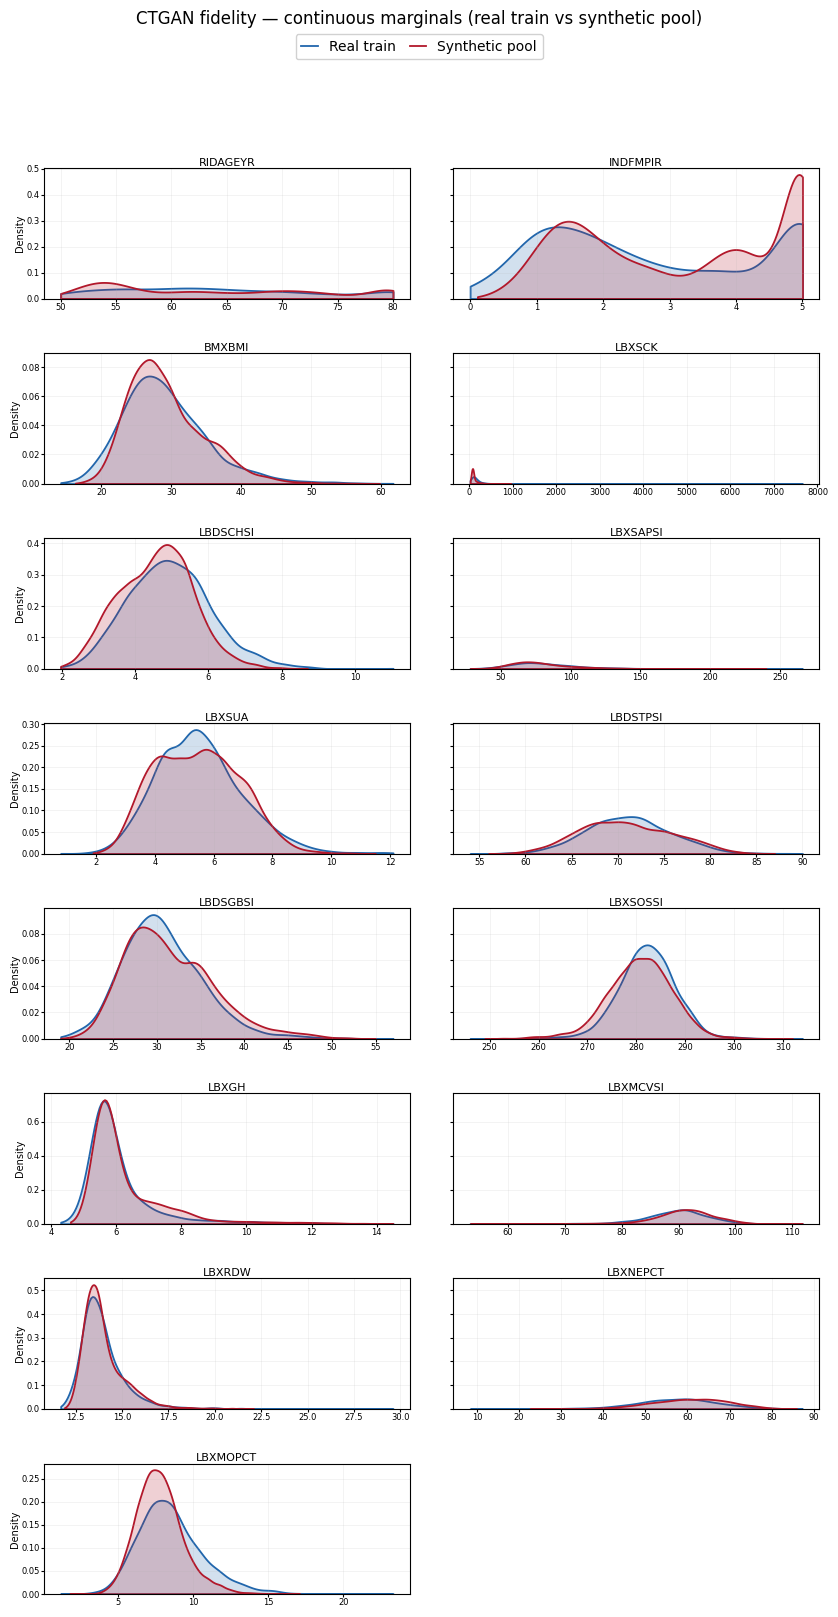

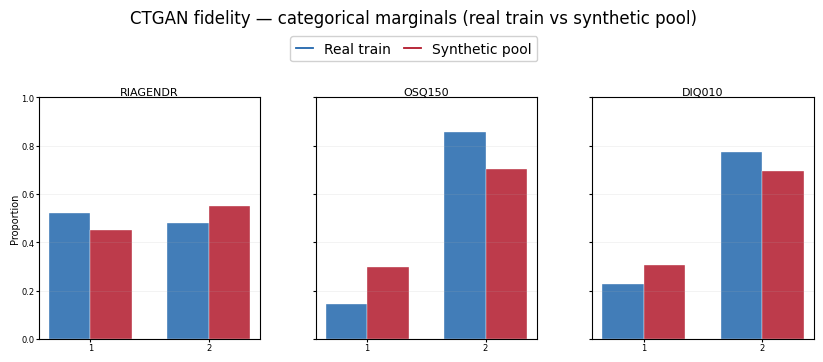

In [6]:
from matplotlib.lines import Line2D

from experiment_utils import CAT_FEATURES, NUM_FEATURES

REAL_COLOR = '#2166ac'
SYN_COLOR = '#b2182b'
PLOT_RC = {
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 10,
}
LABEL_KW = {'labelpad': 1, 'fontsize': 7}


def _plot_categorical_pair(ax, col):
    all_cats = sorted(
        set(train_df[col].dropna().unique()) | set(synthetic_pool[col].dropna().unique())
    )
    real_props = train_df[col].value_counts(normalize=True).reindex(all_cats, fill_value=0)
    syn_props = synthetic_pool[col].value_counts(normalize=True).reindex(all_cats, fill_value=0)
    x = list(range(len(all_cats)))
    bar_w = 0.35
    ax.bar(
        [xi - bar_w / 2 for xi in x],
        real_props.values,
        bar_w,
        color=REAL_COLOR,
        alpha=0.85,
        edgecolor='white',
        linewidth=0.3,
    )
    ax.bar(
        [xi + bar_w / 2 for xi in x],
        syn_props.values,
        bar_w,
        color=SYN_COLOR,
        alpha=0.85,
        edgecolor='white',
        linewidth=0.3,
    )
    ax.set_xticks(x)
    ax.set_xticklabels([int(v) for v in all_cats])
    ax.set_title(col, pad=2)
    ax.set_xlabel('')
    ax.tick_params(axis='both', length=2, pad=1, labelsize=6)
    ax.grid(True, alpha=0.25, linewidth=0.4, axis='y')


def _plot_numeric_pair(ax, col):
    sns.kdeplot(
        data=train_df, x=col, color=REAL_COLOR, fill=True, alpha=0.2,
        linewidth=1.3, ax=ax, legend=False, cut=0,
    )
    sns.kdeplot(
        data=synthetic_pool, x=col, color=SYN_COLOR, fill=True, alpha=0.2,
        linewidth=1.3, ax=ax, legend=False, cut=0,
    )
    ax.set_title(col, pad=2)
    ax.set_xlabel('')
    ax.tick_params(axis='both', length=2, pad=1, labelsize=6)
    ax.grid(True, alpha=0.25, linewidth=0.4)


def _add_legend(fig, y=1.0):
    legend_handles = [
        Line2D([0], [0], color=REAL_COLOR, lw=1.3, label='Real train'),
        Line2D([0], [0], color=SYN_COLOR, lw=1.3, label='Synthetic pool'),
    ]
    fig.legend(
        handles=legend_handles,
        loc='upper center',
        ncol=2,
        framealpha=0.9,
        handlelength=1.2,
        columnspacing=1.0,
        bbox_to_anchor=(0.5, y),
    )


# ── Figure 1: continuous features (KDE) ─────────────────────────────────────
# compare_num_cols = ['RIDAGEYR', 'BMXBMI', 'LBDSCHSI', 'LBXSUA']
compare_num_cols = NUM_FEATURES

n_num = len(compare_num_cols)
nrows = (n_num + 1) // 2
fig_num, axes_num = plt.subplots(nrows, 2, figsize=(10, 2.2 * nrows), squeeze=False)

with plt.rc_context(PLOT_RC):
    for r in range(nrows):
        row_axes = []
        for c in range(2):
            idx = 2 * r + c
            ax = axes_num[r, c]
            if idx >= n_num:
                ax.set_visible(False)
                continue
            _plot_numeric_pair(ax, compare_num_cols[idx])
            row_axes.append(ax)

        if len(row_axes) == 2:
            row_axes[1].sharey(row_axes[0])
            row_axes[0].set_ylabel('Density', **LABEL_KW)
            row_axes[1].set_ylabel('')
            row_axes[1].tick_params(labelleft=False)
        elif row_axes:
            row_axes[0].set_ylabel('Density', **LABEL_KW)

    _add_legend(fig_num, y=1.0)
    fig_num.suptitle(
        'CTGAN fidelity — continuous marginals (real train vs synthetic pool)',
        fontsize=12,
        y=1.01,
    )
    fig_num.subplots_adjust(top=0.92, hspace=0.42, wspace=0.12)
    fig_num.savefig('DATA/figures/ctgan_fidelity_marginals.png', dpi=200, bbox_inches='tight')
    plt.show()

# ── Figure 2: categorical features (bar charts) ─────────────────────────────
compare_cat_cols = CAT_FEATURES

fig_cat, axes_cat = plt.subplots(1, len(compare_cat_cols), figsize=(10, 3.4))
if len(compare_cat_cols) == 1:
    axes_cat = [axes_cat]

with plt.rc_context(PLOT_RC):
    for ax, col in zip(axes_cat, compare_cat_cols):
        _plot_categorical_pair(ax, col)

    for ax in axes_cat[1:]:
        ax.sharey(axes_cat[0])
        ax.set_ylabel('')
        ax.tick_params(labelleft=False)
    axes_cat[0].set_ylabel('Proportion', **LABEL_KW)
    # Shared 0–1 scale so imbalanced codes (OSQ150/DIQ010 = 2) are not clipped
    # to the first panel's autoscale (RIAGENDR max ≈ 0.55).
    axes_cat[0].set_ylim(0, 1.0)
    axes_cat[0].set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    _add_legend(fig_cat, y=1.02)
    fig_cat.suptitle(
        'CTGAN fidelity — categorical marginals (real train vs synthetic pool)',
        fontsize=12,
        y=1.08,
    )
    fig_cat.subplots_adjust(top=0.82, wspace=0.25)
    fig_cat.savefig('DATA/figures/ctgan_fidelity_categorical.png', dpi=200, bbox_inches='tight')
    plt.show()


## 4.6 Evaluate the results

SDV diagnostics compare **real train** rows to the **raw CTGAN output** (same columns as `ctgan_train`: no `SEQN`, `TSCORE`, `TSCORE_ROUNDED`, or `TARGET`).


In [7]:
real_eval = ctgan_train.copy()
synthetic_eval = synthetic_pool[ctgan_cols].copy()

print(f'Real rows: {len(real_eval):,}  |  Synthetic rows: {len(synthetic_eval):,}')
print(f'Columns: {len(ctgan_cols)}')


Real rows: 1,813  |  Synthetic rows: 10,000
Columns: 20


In [8]:
from sdv.evaluation.single_table import run_diagnostic

diagnostic = run_diagnostic(
    real_data=real_eval,
    synthetic_data=synthetic_eval,
    metadata=metadata,
)
diagnostic


Generating report ...

(1/2) Evaluating Data Validity: |██████████| 20/20 [00:00<00:00, 824.88it/s]|
Data Validity Score: 100.0%

(2/2) Evaluating Data Structure: |██████████| 1/1 [00:00<00:00, 1548.28it/s]|
Data Structure Score: 66.67%

Overall Score (Average): 83.33%



In [9]:
from sdv.evaluation.single_table import evaluate_quality

quality_report = evaluate_quality(
    real_eval,
    synthetic_eval,
    metadata,
)
quality_report


Generating report ...

(1/2) Evaluating Column Shapes: |██████████| 20/20 [00:00<00:00, 81.91it/s]|
Column Shapes Score: 90.01%

(2/2) Evaluating Column Pair Trends: |██████████| 190/190 [00:00<00:00, 765.54it/s]|
Column Pair Trends Score: 90.3%

Overall Score (Average): 90.16%



In [10]:
quality_report.get_details('Column Shapes')


,Column,Metric,Score
0,DXXNKBMD,KSComplement,0.928468
1,RIDAGEYR,KSComplement,0.889401
2,INDFMPIR,KSComplement,0.881205
3,BMXBMI,KSComplement,0.956773
4,LBXSCK,KSComplement,0.768295
5,LBDSCHSI,KSComplement,0.857901
6,LBXSAPSI,KSComplement,0.939365
7,LBXSUA,KSComplement,0.948986
8,LBDSTPSI,KSComplement,0.938094
9,LBDSGBSI,KSComplement,0.925853


### 4.6.1 Feature correlations


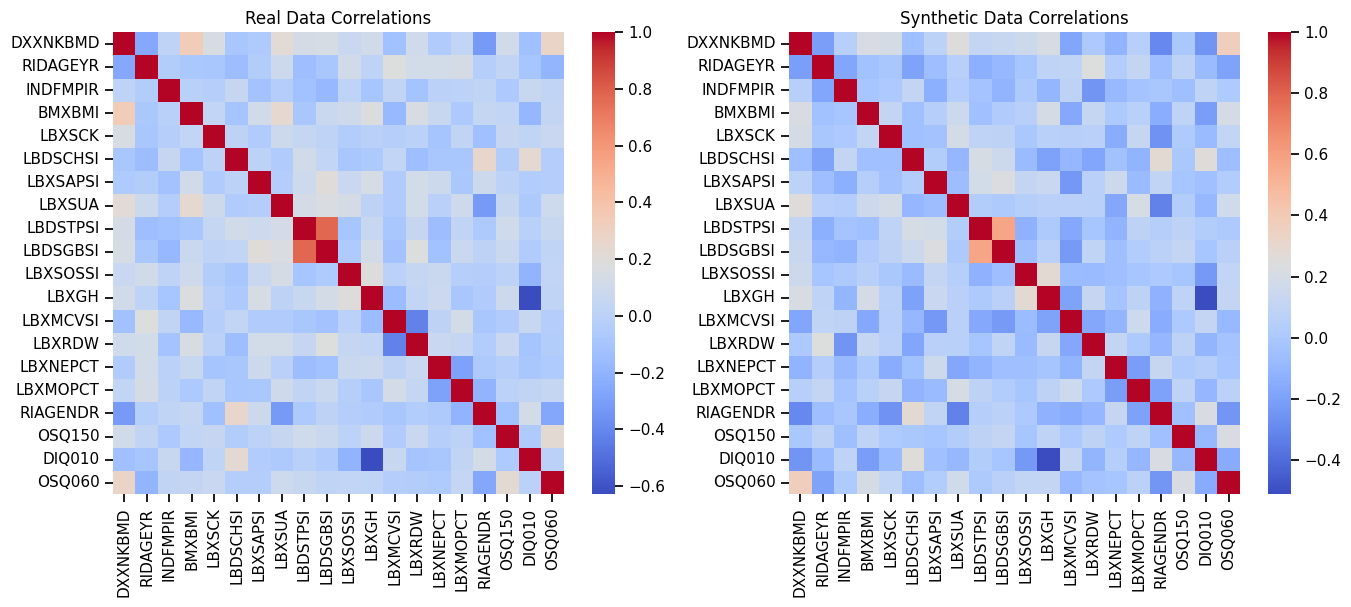

In [11]:
features = real_eval.select_dtypes(include='number').columns.tolist()

real_corr = real_eval[features].corr()
synth_corr = synthetic_eval[features].corr()

with sns.plotting_context('notebook'):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    sns.heatmap(real_corr, annot=False, cmap='coolwarm', ax=ax1)
    ax1.set_title('Real Data Correlations')

    sns.heatmap(synth_corr, annot=False, cmap='coolwarm', ax=ax2)
    ax2.set_title('Synthetic Data Correlations')

    fig.savefig('DATA/figures/ctgan_fidelity_correlations.png', dpi=200, bbox_inches='tight')
    plt.show()


**Next:** `5_MODELS_EQUIVALENCE.ipynb` compares Real vs Synthetic vs Augmented training at full train size.